# Object detection pipeline (ArTaxOr)

## Colab setup
Use a GPU runtime (Runtime → Change runtime type → T4 GPU). torch/torchvision come preinstalled.

In [1]:
!pip install -q lightning torchmetrics pycocotools kagglehub

Download the dataset (~12 GB) to the runtime's local disk. Public dataset, so no Kaggle login should be needed;
if kagglehub asks for credentials, add `KAGGLE_USERNAME` / `KAGGLE_KEY` in Colab secrets.

In [2]:
import kagglehub

DATA_DIR = kagglehub.dataset_download("mistag/arthropod-taxonomy-orders-object-detection-dataset")
print(DATA_DIR)
!ls {DATA_DIR}

Using Colab cache for faster access to the 'arthropod-taxonomy-orders-object-detection-dataset' dataset.
/kaggle/input/arthropod-taxonomy-orders-object-detection-dataset
ArTaxOr


In [3]:
import argparse
import json
import os
import random
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Dict, List, Tuple

import torch
from torch import Tensor
from torch.utils.data import DataLoader, Dataset

import torchvision
from torchvision.transforms import functional as F

import lightning.pytorch as pl
from lightning.pytorch.callbacks import LearningRateMonitor, ModelCheckpoint

from torchmetrics.detection.mean_ap import MeanAveragePrecision
from PIL import Image

In [4]:
# -----------------------------
# Utils
# -----------------------------
def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def collate_fn(batch):
    # batch: List[(image, target)]
    # BUG: images, targets, _ = zip(*batch)  -> ValueError: not enough values to unpack
    images, targets = zip(*batch)
    return list(images), list(targets)

In [14]:
# -----------------------------
# Dataset
# -----------------------------
@dataclass
class Sample:
    image_path: Path
    ann_path: Path
    order_name: str


class ArTaxOrVoTTDataset(Dataset):
    """
    Reads VoTT JSON per image. Expected keys:
      - data["asset"]["name"] -> image filename
      - data["regions"][i]["boundingBox"] -> {left, top, width, height}
      - data["regions"][i]["tags"] -> ["OrderName", ...] (optional; we fallback to folder name)
    """

    def __init__(
        self,
        samples: List[Sample],
        class_to_idx: Dict[str, int],
        train: bool = True,
        vflip_p: float = 0.5,
    ):
        self.samples = samples
        self.class_to_idx = class_to_idx
        self.train = train
        # self.hflip_p - old name, renamed into vflip
        self.vflip_p = vflip_p

    def __len__(self) -> int:
        return len(self.samples)

    def _read_target(self, ann_path: Path, fallback_label: str) -> Tuple[Tensor, Tensor]:
        data = json.loads(ann_path.read_text(encoding="utf-8"))

        boxes: List[List[float]] = []
        labels: List[int] = []

        for reg in data.get("regions", []):
            bb = reg.get("boundingBox", None)
            if bb is None:
                continue

            left = float(bb["left"])
            top = float(bb["top"])
            width = float(bb["width"])
            height = float(bb["height"])
            x1, y1 = left, top
            # BUG: x2, y2 = left + height, top + width
            x2, y2 = left + width, top + height

            tag_list = reg.get("tags", []) or []
            label_name = tag_list[0] if len(tag_list) > 0 else fallback_label
            if label_name not in self.class_to_idx:
                label_name = fallback_label

            # BUG: boxes.append([x1, y2, x2, y1])
            boxes.append([x1, y1, x2, y2])
            labels.append(self.class_to_idx[label_name])

        if len(boxes) == 0:
            raise ValueError(f"No boxes found in {ann_path}")

        return torch.tensor(boxes, dtype=torch.float32), torch.tensor(labels, dtype=torch.int64)

    def __getitem__(self, idx: int) -> Tuple[Tensor, Dict[str, Tensor]]:
        s = self.samples[idx]

        data = json.loads(s.ann_path.read_text(encoding="utf-8"))
        img_name = data.get("asset", {}).get("name", s.image_path.name)
        img_path = s.image_path.parent / img_name

        img = Image.open(img_path).convert("RGB")

        # BUG: h, w = img.size
        # All bounding boxes should have positive height and width. Found invalid box [799.5, 645.9769897460938, 799.5, 817.62451171875] for target at index 2.
        w, h = img.size

        boxes, labels = self._read_target(s.ann_path, fallback_label=s.order_name)

        # Basic augmentation: vertical flip
        if self.train and random.random() < self.vflip_p:
            img = F.vflip(img)
            boxes[:, [1, 3]] = torch.tensor([h, h], dtype=torch.float32) - boxes[:, [3, 1]]

        img_t = F.to_tensor(img)
        boxes[:, 0::2] = boxes[:, 0::2].clamp(0, w)
        boxes[:, 1::2] = boxes[:, 1::2].clamp(0, h)

        target: Dict[str, Tensor] = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx], dtype=torch.int64),
            "area": (boxes[:, 2] - boxes[:, 0]).clamp(min=0) * (boxes[:, 3] - boxes[:, 1]).clamp(min=0),
            "iscrowd": torch.zeros((boxes.shape[0],), dtype=torch.int64),
        }
        return img_t, target


class ArTaxOrDataModule(pl.LightningDataModule):
    def __init__(
        self,
        data_dir: str,
        batch_size: int = 2,
        num_workers: int = 4,
        val_split: float = 0.1,
        seed: int = 42,
    ):
        super().__init__()
        self.data_dir = Path(data_dir)
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.val_split = val_split
        self.seed = seed

        self.class_to_idx: Dict[str, int] = {}
        self.idx_to_class: Dict[int, str] = {}
        self.train_ds: Dataset | None = None
        self.val_ds: Dataset | None = None

    def _discover_orders(self, artaxor_root: Path) -> List[str]:
        # class folders are the "orders"
        orders = []
        for d in artaxor_root.iterdir():
            if d.is_dir() and (d / "annotations").exists():
                orders.append(d.name)
        orders = sorted(orders)
        if not orders:
            raise FileNotFoundError(f"No order folders with 'annotations' found under {artaxor_root}")
        return orders

    def _build_samples(self, artaxor_root: Path, orders: List[str]) -> List[Sample]:
        samples: List[Sample] = []
        for order in orders:
            order_dir = artaxor_root / order
            ann_dir = order_dir / "annotations"
            if not ann_dir.exists():
                continue
            for ann_path in ann_dir.rglob("*.json"):
                samples.append(Sample(image_path=order_dir / "dummy.jpg", ann_path=ann_path, order_name=order))
        if not samples:
            raise FileNotFoundError(f"No JSON annotations found under {artaxor_root}")
        return samples

    def setup(self, stage: str | None = None) -> None:
        artaxor_root = self.data_dir / "ArTaxOr"
        if not artaxor_root.exists():
            # Sometimes users point directly at ArTaxOr
            if (self.data_dir / "annotation").exists():
                artaxor_root = self.data_dir
            else:
                raise FileNotFoundError(f"Expected ArTaxOr folder under {self.data_dir}")

        orders = self._discover_orders(artaxor_root)
        self.class_to_idx = {name: i + 1 for i, name in enumerate(orders)}
        self.idx_to_class = {v: k for k, v in self.class_to_idx.items()}

        all_samples = self._build_samples(artaxor_root, orders)

        rng = random.Random(self.seed)
        rng.shuffle(all_samples)
        n_val = max(1, int(len(all_samples) * self.val_split))
        val_samples = all_samples[:n_val]
        train_samples = all_samples[n_val:]

        self.train_ds = ArTaxOrVoTTDataset(train_samples, self.class_to_idx, train=True)
        self.val_ds = ArTaxOrVoTTDataset(val_samples, self.class_to_idx, train=False)

    def train_dataloader(self) -> DataLoader:
        assert self.train_ds is not None
        return DataLoader(
            self.train_ds,
            batch_size=self.batch_size,
            shuffle=True,
            num_workers=self.num_workers,
            pin_memory=True,
            collate_fn=collate_fn,
        )

    def val_dataloader(self) -> DataLoader:
        assert self.val_ds is not None
        return DataLoader(
            self.val_ds,
            batch_size=self.batch_size,
            shuffle=False,
            num_workers=self.num_workers,
            pin_memory=True,
            collate_fn=collate_fn,
        )

In [15]:
# -----------------------------
# Lightning module
# -----------------------------
class FasterRCNNLit(pl.LightningModule):
    def __init__(
        self,
        num_classes: int,
        lr: float = 1e-6,
        weight_decay: float = 1e-4,
    ):
        super().__init__()
        self.save_hyperparameters()

        model = torchvision.models.detection.fasterrcnn_mobilenet_v3_large_fpn(
            weights=torchvision.models.detection.FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT
        )
        in_features = model.roi_heads.box_predictor.cls_score.in_features
        model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(
            in_features, num_classes
        )
        self.model = model

        self.map_metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")

    def forward(self, images: List[Tensor], targets: List[Dict[str, Tensor]] | None = None):
        return self.model(images, targets)

    def training_step(self, batch, batch_idx):
        images, targets = batch
        loss_dict = self.model(images, targets)  # returns losses in train mode
        loss = sum(loss_dict.values())
        self.log("train/loss", loss, prog_bar=True, on_step=True, on_epoch=True)
        for k, v in loss_dict.items():
            self.log(f"train/{k}", v, prog_bar=False, on_step=False, on_epoch=True)
        return loss

    @torch.no_grad()
    def validation_step(self, batch, batch_idx):
        images, targets = batch
        preds = self.model(images)
        self.map_metric.update(preds, targets)

    def on_validation_epoch_end(self):
        metrics = self.map_metric.compute()
        self.log("val/map", metrics["map"], prog_bar=True)
        self.log("val/map_50", metrics["map_50"], prog_bar=True)
        self.map_metric.reset()

    def configure_optimizers(self):
        params = [p for p in self.model.parameters() if p.requires_grad]
        opt = torch.optim.AdamW(params, lr=self.hparams.lr, weight_decay=self.hparams.weight_decay)
        sch = torch.optim.lr_scheduler.StepLR(opt, step_size=5, gamma=0.01)
        return {"optimizer": opt, "lr_scheduler": sch}

In [32]:
def main(args: argparse.Namespace):
    seed_everything(args.seed)

    dm = ArTaxOrDataModule(
        data_dir=args.data_dir,
        batch_size=args.batch_size,
        num_workers=args.num_workers,
        val_split=args.val_split,
        seed=args.seed,
    )
    dm.setup()

    num_classes = len(dm.class_to_idx) + 1  # + background (0)
    lit = FasterRCNNLit(num_classes=num_classes, lr=args.lr)

    ckpt = ModelCheckpoint(monitor="val/map_50", mode="max", save_top_k=1, filename="frcnn-{epoch:02d}-{val/map50:.4f}")
    lrmon = LearningRateMonitor(logging_interval="epoch")

    trainer = pl.Trainer(
        max_epochs=args.max_epochs,
        accelerator="auto",
        devices="auto",
        callbacks=[ckpt, lrmon],
        log_every_n_steps=20,
        val_check_interval=200,
        limit_val_batches=0.25,
    )
    trainer.fit(lit, datamodule=dm)
    print("Best checkpoint:", ckpt.best_model_path)

## Config
Replaces `argparse` (`parse_args()` fails inside a notebook kernel). Same defaults as the original CLI.

In [33]:
args = argparse.Namespace(
    data_dir=DATA_DIR,  # Path containing ArTaxOr/...
    batch_size=4,
    num_workers=10,
    val_split=0.1,
    max_epochs=20,
    lr=1e-6,
    seed=42,
)

In [ ]:
%load_ext tensorboard
%tensorboard --logdir lightning_logs

In [35]:
main(args)

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name       ┃ Type                 ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model      │ FasterRCNN           │ 19.0 M │ train │     0 │
│ 1 │ map_metric │ MeanAveragePrecision │      0 │ train │     0 │
└───┴────────────┴──────────────────────┴────────┴───────┴───────┘

Trainable params: 18.9 M                                                                                           
Non-trainable params: 58.9 K                                                                                       
Total params: 19.0 M                                                                                               
Total estimated model params size (MB): 75.844                                                                     
Modules in train mode: 281                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO: 
Detected KeyboardInterrupt, attempting graceful shutdown ...
INFO:lightning.pytorch.utilities.rank_zero:
Detected KeyboardInterrupt, attempting graceful shutdown ...


ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/call.py", line 49, in _call_and_handle_interrupt
    return trainer_fn(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/trainer.py", line 630, in _fit_impl
    self._run(model, ckpt_path=ckpt_path, weights_only=weights_only)
    ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/trainer.py", line 1079, in _run
    results = self._run_stage()
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/trainer.py", line 1123, in _run_stage
    self.fit_loop.run()
    ~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py", line 217, in run
    self.advance()
    ~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py", line 469, in advance
    self.

TypeError: object of type 'NoneType' has no len()

## Training curves

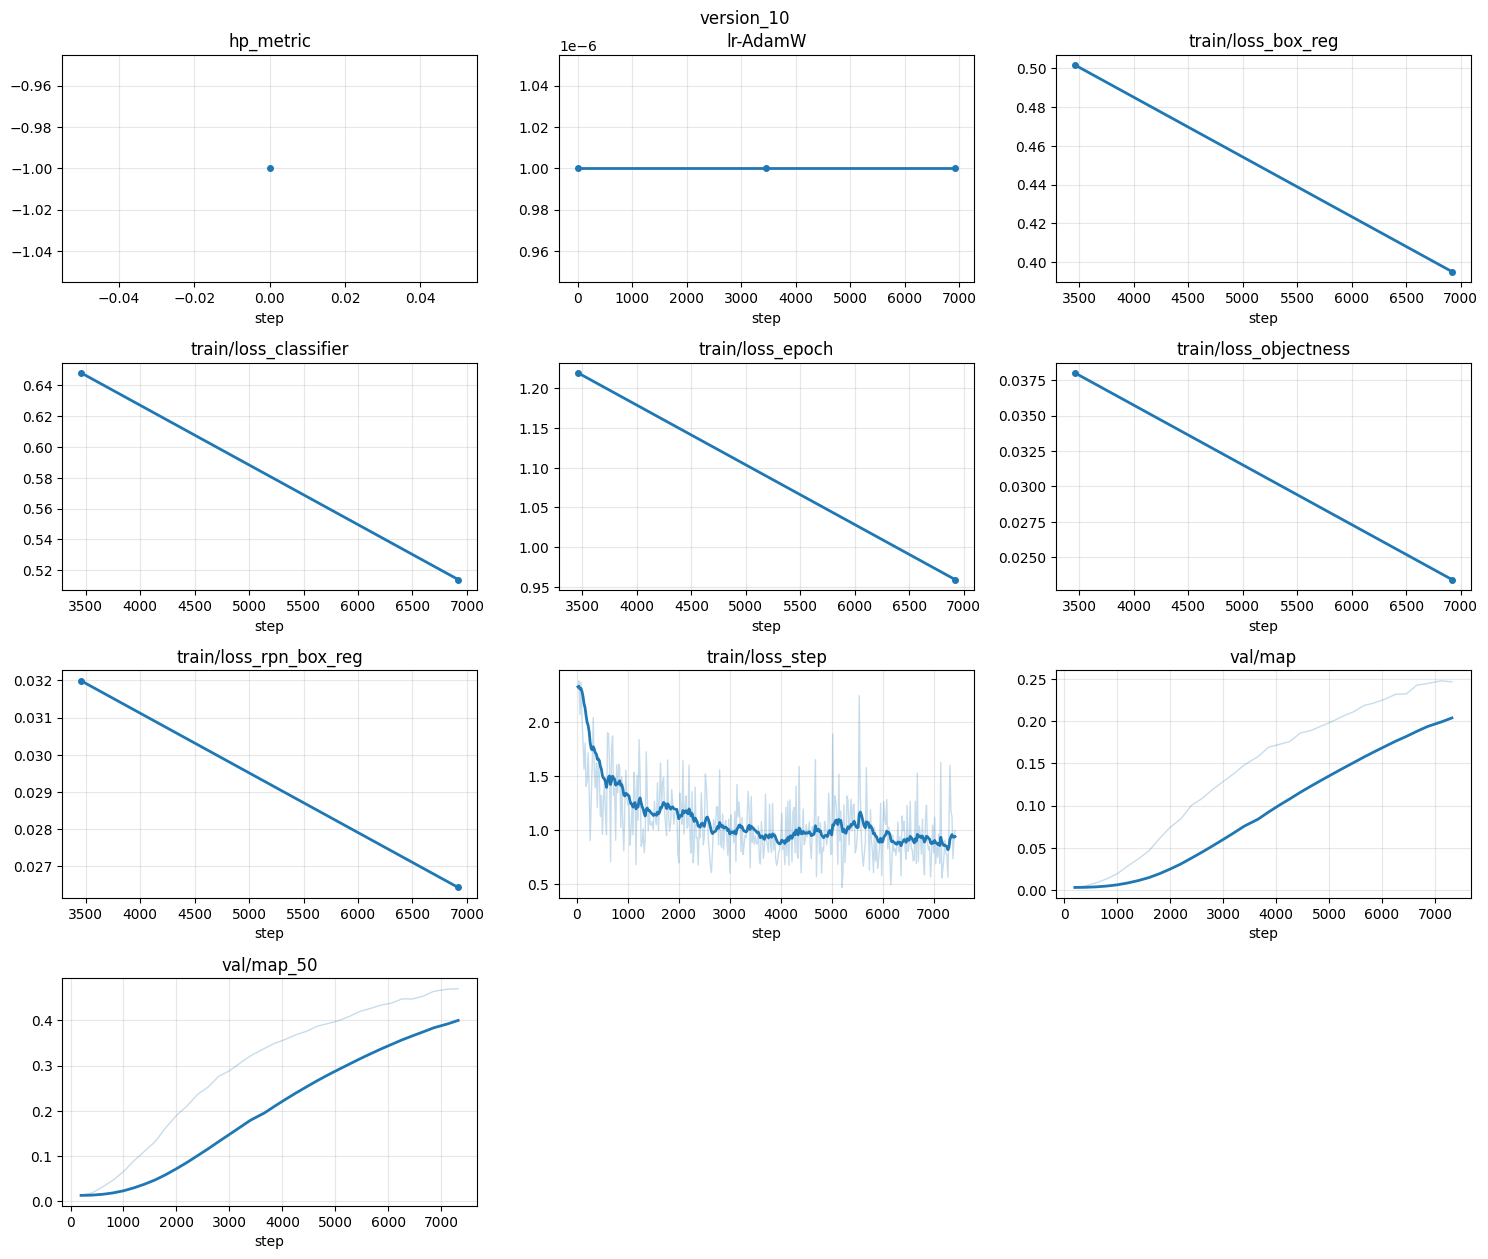

In [36]:
import math

import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator


def plot_latest_run(log_dir: str = "lightning_logs", smooth: float = 0.9) -> None:
    runs = sorted(Path(log_dir).glob("version_*"), key=lambda p: int(p.name.split("_")[1]))
    if not runs:
        raise FileNotFoundError(f"No runs found under {log_dir}")
    run = runs[-1]

    ea = EventAccumulator(str(run), size_guidance={"scalars": 0})  # 0 = load all points
    ea.Reload()
    tags = [t for t in sorted(ea.Tags()["scalars"]) if t != "epoch"]

    cols = 3
    rows = math.ceil(len(tags) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.2 * rows), squeeze=False)
    for ax, tag in zip(axes.flat, tags):
        events = ea.Scalars(tag)
        steps = [e.step for e in events]
        values = [e.value for e in events]
        if len(values) > 20:
            # noisy per-step series: raw values faint, exponential moving average on top
            ema, s = [], values[0]
            for v in values:
                s = smooth * s + (1 - smooth) * v
                ema.append(s)
            ax.plot(steps, values, color="C0", alpha=0.25, lw=1)
            ax.plot(steps, ema, color="C0", lw=2)
        else:
            ax.plot(steps, values, color="C0", lw=2, marker="o", ms=4)
        ax.set_title(tag)
        ax.set_xlabel("step")
        ax.grid(alpha=0.3)
    for ax in axes.flat[len(tags):]:
        ax.axis("off")
    fig.suptitle(run.name)
    fig.tight_layout()
    plt.show()


plot_latest_run()

## Debugging

In [ ]:
def test_bboxes():
  dm = ArTaxOrDataModule(
      data_dir=args.data_dir,
      batch_size=args.batch_size,
      num_workers=args.num_workers,
      val_split=args.val_split,
      seed=args.seed,
  )
  dm.setup()

  ds = dm.train_dataloader().dataset   # or however you get the train dataset
  ds.train = False                      # turn off random flip so results are repeatable
  for i in range(len(ds)):
      img, t = ds[i]
      b = t["boxes"]
      bad = (b[:, 2] <= b[:, 0]) | (b[:, 3] <= b[:, 1])
      if bad.any():
          s = ds.samples[i]
          print(i, s.ann_path, "img (C,H,W):", tuple(img.shape))
          print("  bad boxes:", b[bad].tolist())
          print("  raw:", ds._read_target(s.ann_path, s.order_name)[0][bad].tolist())
          break

test_bboxes()